Menor custo: robôs=5.00, vel=1.00 m/s | custo=R$ 133.01 mil | tempo=63.97 min
Intermediária: robôs=6.29, vel=3.31 m/s | custo=R$ 245.02 mil | tempo=31.15 min
Menor tempo: robôs=15.60, vel=3.90 m/s | custo=R$ 511.29 mil | tempo=17.96 min


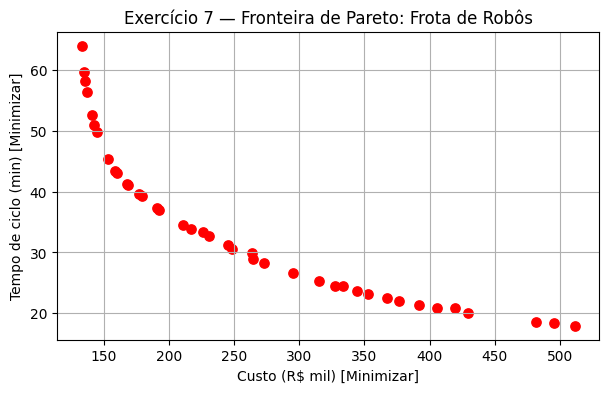

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize


class FrotaRobosProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=2, n_ieq_constr=1,
                         xl=np.array([5.0, 1.0]), xu=np.array([50.0, 4.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        n, v = x[0], x[1]
        f1_custo = n * 25.0 + (v ** 2) * 8.0
        f2_tempo = 120.0 / n + 40.0 / v
        g1 = n * v ** 1.5 - 120.0          # consumo <= 120
        out["F"] = [f1_custo, f2_tempo]
        out["G"] = [g1]


res = minimize(FrotaRobosProblem(), NSGA2(pop_size=40),
               termination=('n_gen', 60), seed=1)

# Ordena pela frente de Pareto (custo crescente)
idx = np.argsort(res.F[:, 0])
F, X = res.F[idx], res.X[idx]

escolhidas = {
    "Menor custo":        0,
    "Intermediária":      len(F) // 2,
    "Menor tempo":        len(F) - 1,
}
for nome, i in escolhidas.items():
    print(f"{nome}: robôs={X[i,0]:.2f}, vel={X[i,1]:.2f} m/s | "
          f"custo=R$ {F[i,0]:.2f} mil | tempo={F[i,1]:.2f} min")

plt.figure(figsize=(7, 4))
plt.scatter(F[:, 0], F[:, 1], color='red', s=45)
plt.title("Exercício 7 — Fronteira de Pareto: Frota de Robôs")
plt.xlabel("Custo (R$ mil) [Minimizar]")
plt.ylabel("Tempo de ciclo (min) [Minimizar]")
plt.grid(True)
plt.savefig("pareto_frota_robos.png", dpi=150, bbox_inches="tight")
plt.show()